<a href="https://colab.research.google.com/github/rojasathyanjali-arch/qkrishi-os-challenge/blob/main/Roja_Sathyanjali_Assignment_ipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment

## Hardware Characterization and Region Recommendation

### Background

Modern hardware systems are not perfectly uniform.

Different regions of a device may exhibit different operational characteristics due to calibration, reliability, connectivity, and other factors.

You are provided with:

- a calibration snapshot
- topology information

Your task is to analyze the provided information and make a recommendation.

---

### Files Provided

- ibm_kingston_calibrations.csv
- ibm_kingston_topology_complete.json

---

### Deliverables

Your notebook must contain:

1. Dataset analysis
2. Methodology
3. One recommended 16-qubit region
4. One recommended 32-qubit region
5. Written responses to all questions

---
### Notes

The provided data contains sufficient information to make a reasonable recommendation.

You may use any information available in the provided files.

Document your analysis in the notebook.

## Instructions

You may use:

- Python
- NumPy
- Pandas
- NetworkX
- SciPy
- Any standard open-source package

You may add additional cells as required.

The final notebook should execute from top to bottom without modification.

In [ ]:
import json
import numpy as np
import pandas as pd
import networkx as nx

In [ ]:
import os
os.listdir('/content')

['.config',
 'ibm_kingston_topology_complete .json',
 'ibm_kingston_calibrations_2026-03-31T09_24_11Z.xls',
 'sample_data']

In [ ]:
import os

for name in os.listdir('/content'):
    print(repr(name))

'.config'
'ibm_kingston_topology_complete .json'
'ibm_kingston_calibrations_2026-03-31T09_24_11Z.xls'
'sample_data'


In [ ]:
CALIBRATION_FILE = r"ibm_kingston_calibrations_2026-03-31T09_24_11Z.xls"
TOPOLOGY_FILE = r"ibm_kingston_topology_complete .json"

df = pd.read_csv(CALIBRATION_FILE)

with open(TOPOLOGY_FILE) as f:
    topology = json.load(f)

print(df.shape)
df.head()

(156, 19)


,Qubit,T1 (us),T2 (us),Readout assignment error,Prob meas0 prep1,Prob meas1 prep0,Readout length (ns),ID error,Single-qubit gate length (ns),RX error,Z-axis rotation (rz) error,√x (sx) error,Pauli-X error,CZ error,Gate length (ns),RZZ error,MEASURE error,MEASURE_2 error,Operational
0,0,290.800821,298.140732,0.011475,0.014404,0.008545,2280,0.000205,32,0.000205,0,0.000205,0.000205,1:0.0010167457696165227,1:68,1:0.0010602119472144789,0.011475,0.016602,Yes
1,1,372.822654,437.021834,0.164795,0.100342,0.229248,2280,0.000181,32,0.000181,0,0.000181,0.000181,2:0.0009609959626648845;0:0.0010167457696165227,2:68;0:68,2:0.0009016463575797495;0:0.0010602119472144789,0.164795,0.081055,Yes
2,2,305.112602,107.784842,0.008057,0.010742,0.005371,2280,0.000100,32,0.000100,0,0.000100,0.000100,1:0.0009609959626648845;3:0.0012523142615088745,1:68;3:68,1:0.0009016463575797495;3:0.000930022916350165,0.008057,0.008057,Yes
3,3,354.894616,483.530444,0.008301,0.011475,0.005127,2280,0.000243,32,0.000243,0,0.000243,0.000243,16:0.0012413347520312812;2:0.00125231426150887...,16:68;2:68;4:68,16:0.001184823243668115;2:0.000930022916350165...,0.008301,0.007324,Yes
4,4,316.778855,53.238112,0.022339,0.018799,0.025879,2280,0.000282,32,0.000282,0,0.000282,0.000282,3:0.002007963045889627;5:0.002521856056860644,3:68;5:68,3:0.0018174791538967394;5:0.0026275206583171173,0.022339,0.013916,Yes


# Part 1

## Initial Dataset Analysis

Perform an initial analysis of the calibration snapshot.



In [ ]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values in each column:")
print(df.isnull().sum())

print("\nSummary of numerical data:")
display(df.describe())

print("\nFirst 10 qubits:")
display(df.head(10))

Dataset shape: (156, 19)

Column names:
['Qubit', 'T1 (us)', 'T2 (us)', 'Readout assignment error', 'Prob meas0 prep1', 'Prob meas1 prep0', 'Readout length (ns)', 'ID error', 'Single-qubit gate length (ns)', 'RX error', 'Z-axis rotation (rz) error', '√x (sx) error', 'Pauli-X error', 'CZ error', 'Gate length (ns)', 'RZZ error', 'MEASURE error', 'MEASURE_2 error', 'Operational']

Missing values in each column:
Qubit                            0
T1 (us)                          1
T2 (us)                          1
Readout assignment error         0
Prob meas0 prep1                 0
Prob meas1 prep0                 0
Readout length (ns)              0
ID error                         3
Single-qubit gate length (ns)    0
RX error                         3
Z-axis rotation (rz) error       0
√x (sx) error                    3
Pauli-X error                    3
CZ error                         3
Gate length (ns)                 0
RZZ error                        4
MEASURE error               

,Qubit,T1 (us),T2 (us),Readout assignment error,Prob meas0 prep1,Prob meas1 prep0,Readout length (ns),ID error,Single-qubit gate length (ns),RX error,Z-axis rotation (rz) error,√x (sx) error,Pauli-X error,MEASURE error,MEASURE_2 error
count,156.000000,155.000000,155.000000,156.000000,156.000000,156.000000,156.0,153.000000,156.0,153.000000,156.0,153.000000,153.000000,156.000000,156.000000
mean,77.500000,271.047301,171.809415,0.024635,0.023470,0.026272,2280.0,0.000302,32.0,0.000302,0.0,0.000302,0.000302,0.024635,0.022345
std,45.177428,81.323694,114.423826,0.060042,0.049109,0.092053,0.0,0.000486,0.0,0.000486,0.0,0.000486,0.000486,0.060042,0.050535
min,0.000000,65.887474,11.926602,0.003174,0.002686,0.000488,2280.0,0.000087,32.0,0.000087,0.0,0.000087,0.000087,0.003174,0.001465
25%,38.750000,212.142753,81.208905,0.006226,0.007263,0.003662,2280.0,0.000172,32.0,0.000172,0.0,0.000172,0.000172,0.006226,0.005615
50%,77.500000,280.249093,134.260653,0.009277,0.010498,0.007690,2280.0,0.000214,32.0,0.000214,0.0,0.000214,0.000214,0.009277,0.008423
75%,116.250000,336.066393,242.317056,0.018982,0.018799,0.017639,2280.0,0.000297,32.0,0.000297,0.0,0.000297,0.000297,0.018982,0.018616
max,155.000000,479.729813,488.482105,0.504883,0.498047,0.988525,2280.0,0.005838,32.0,0.005838,0.0,0.005838,0.005838,0.504883,0.500000



First 10 qubits:


,Qubit,T1 (us),T2 (us),Readout assignment error,Prob meas0 prep1,Prob meas1 prep0,Readout length (ns),ID error,Single-qubit gate length (ns),RX error,Z-axis rotation (rz) error,√x (sx) error,Pauli-X error,CZ error,Gate length (ns),RZZ error,MEASURE error,MEASURE_2 error,Operational
0,0,290.800821,298.140732,0.011475,0.014404,0.008545,2280,0.000205,32,0.000205,0,0.000205,0.000205,1:0.0010167457696165227,1:68,1:0.0010602119472144789,0.011475,0.016602,Yes
1,1,372.822654,437.021834,0.164795,0.100342,0.229248,2280,0.000181,32,0.000181,0,0.000181,0.000181,2:0.0009609959626648845;0:0.0010167457696165227,2:68;0:68,2:0.0009016463575797495;0:0.0010602119472144789,0.164795,0.081055,Yes
2,2,305.112602,107.784842,0.008057,0.010742,0.005371,2280,0.000100,32,0.000100,0,0.000100,0.000100,1:0.0009609959626648845;3:0.0012523142615088745,1:68;3:68,1:0.0009016463575797495;3:0.000930022916350165,0.008057,0.008057,Yes
3,3,354.894616,483.530444,0.008301,0.011475,0.005127,2280,0.000243,32,0.000243,0,0.000243,0.000243,16:0.0012413347520312812;2:0.00125231426150887...,16:68;2:68;4:68,16:0.001184823243668115;2:0.000930022916350165...,0.008301,0.007324,Yes
4,4,316.778855,53.238112,0.022339,0.018799,0.025879,2280,0.000282,32,0.000282,0,0.000282,0.000282,3:0.002007963045889627;5:0.002521856056860644,3:68;5:68,3:0.0018174791538967394;5:0.0026275206583171173,0.022339,0.013916,Yes
5,5,133.141405,61.718647,0.006836,0.009521,0.004150,2280,0.000336,32,0.000336,0,0.000336,0.000336,6:0.002482708269532563;4:0.002521856056860644,6:68;4:68,6:0.002667745536042654;4:0.0026275206583171173,0.006836,0.008545,Yes
6,6,262.445610,123.580780,0.010498,0.010010,0.010986,2280,0.000225,32,0.000225,0,0.000225,0.000225,5:0.002482708269532563;7:0.007143246937313497,5:68;7:80,5:0.002667745536042654;7:0.010732557806185289,0.010498,0.015869,Yes
7,7,383.084498,77.176985,0.021362,0.021484,0.021240,2280,0.000291,32,0.000291,0,0.000291,0.000291,17:0.005846746467566055;6:0.007143246937313497...,17:68;6:80;8:68,17:0.004331245341646528;6:0.010732557806185289...,0.021362,0.016846,Yes
8,8,288.398879,84.167358,0.005737,0.010010,0.001465,2280,0.000283,32,0.000283,0,0.000283,0.000283,9:0.0023246380453462445;7:0.007194008488652814,9:68;7:68,9:0.0019170841750110468;7:0.0042280283951493525,0.005737,0.004883,Yes
9,9,128.251925,35.647702,0.005859,0.008057,0.003662,2280,0.000547,32,0.000547,0,0.000547,0.000547,8:0.0023246380453462445;10:0.004617037541619767,8:68;10:68,8:0.0019170841750110468;10:0.005229698133982857,0.005859,0.007568,Yes


## Observations
- The calibration dataset contains 156 rows and 19 columns.
- The dataset includes qubit IDs, T1 and T2 coherence times, readout assignment errors, and single-qubit and two-qubit gate error measurements.
- Some calibration metrics contain missing values. These should be handled carefully during analysis.
- Calibration performance varies across qubits, so the hardware should not be treated as uniform.
- Regions should be compared using calibration quality and physical connectivity, rather than selecting qubits based on a single metric.


# Part 2

## Hardware Representation

Construct any representation(s) you believe are useful for this assignment.

Explain any design choices you make.

In [ ]:
print("Calibration columns:")
print(df.columns.tolist())

print("\nTopology data type:")
print(type(topology))

print("\nTopology structure:")
if isinstance(topology, dict):
    print("Keys:", list(topology.keys()))
    for key, value in topology.items():
        print(f"\n{key}:")
        if isinstance(value, (dict, list)):
            print("Type:", type(value).__name__)
            print("Sample:", str(value)[:500])
        else:
            print(value)
elif isinstance(topology, list):
    print("Number of items:", len(topology))
    print("Sample:", topology[:3])
else:
    print(str(topology)[:1000])

Calibration columns:
['Qubit', 'T1 (us)', 'T2 (us)', 'Readout assignment error', 'Prob meas0 prep1', 'Prob meas1 prep0', 'Readout length (ns)', 'ID error', 'Single-qubit gate length (ns)', 'RX error', 'Z-axis rotation (rz) error', '√x (sx) error', 'Pauli-X error', 'CZ error', 'Gate length (ns)', 'RZZ error', 'MEASURE error', 'MEASURE_2 error', 'Operational']

Topology data type:
<class 'dict'>

Topology structure:
Keys: ['device_name', 'num_qubits', 'native_gates', 'max_shots', 'coupling_map_directed', 'coupling_map_undirected', 'adjacency', 'degree', 'summary', 'target_crosscheck']

device_name:
ibm_kingston

num_qubits:
156

native_gates:
Type: list
Sample: ['cz', 'id', 'rz', 'sx', 'x']

max_shots:
100000

coupling_map_directed:
Type: list
Sample: [[0, 1], [1, 0], [1, 2], [2, 1], [2, 3], [3, 2], [3, 4], [3, 16], [4, 3], [4, 5], [5, 4], [5, 6], [6, 5], [6, 7], [7, 6], [7, 8], [7, 17], [8, 7], [8, 9], [9, 8], [9, 10], [10, 9], [10, 11], [11, 10], [11, 12], [11, 18], [12, 11], [12, 13],

Number of qubits: 156
Number of connections: 176
Connected components: 1


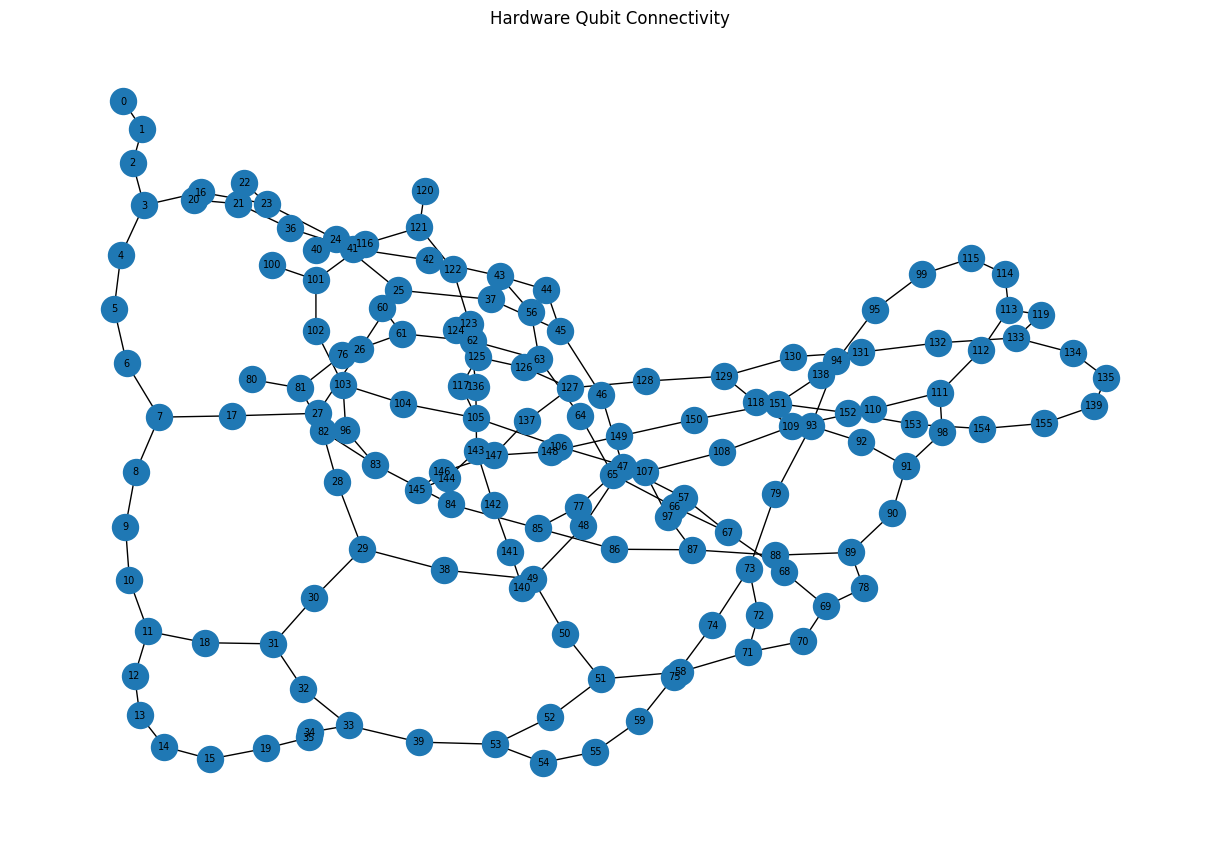

In [ ]:
import networkx as nx
import matplotlib.pyplot as plt

G = nx.Graph()

# Add qubits as nodes
G.add_nodes_from(df["Qubit"].dropna().astype(int))

# Add connections between qubits
edges = topology["coupling_map_undirected"]
G.add_edges_from(tuple(edge) for edge in edges)

# Attach calibration values to each qubit
for _, row in df.iterrows():
    q = int(row["Qubit"])
    if q in G:
        G.nodes[q]["T1"] = row["T1 (us)"]
        G.nodes[q]["T2"] = row["T2 (us)"]
        G.nodes[q]["readout_error"] = row["Readout assignment error"]

print("Number of qubits:", G.number_of_nodes())
print("Number of connections:", G.number_of_edges())
print("Connected components:", nx.number_connected_components(G))

plt.figure(figsize=(12, 8))
pos = nx.spring_layout(G, seed=42)
nx.draw(G, pos, with_labels=True, node_size=350, font_size=7)
plt.title("Hardware Qubit Connectivity")
plt.show()

## Representation Notes
The hardware is represented using an undirected graph. Each node represents a physical qubit, and each edge represents a connection between two qubits. Calibration values such as T1, T2, and readout error are stored as node attributes. This representation helps analyze hardware connectivity and select suitable regions.

# Part 3

Identify one candidate 16-qubit region and one candidate 32-qubit region.

You may use any information available in the provided files.

Provide one recommended 16-qubit region and one recommended 32-qubit region.

Document your methodology.

In [ ]:
import numpy as np
import pandas as pd
import networkx as nx

# Create a lookup table for calibration data
cal = df.set_index("Qubit")

# Score each qubit using T1, T2, and readout error
score_df = cal[["T1 (us)", "T2 (us)",
                "Readout assignment error"]].copy()

score_df = score_df.dropna()

score_df["score"] = (
    score_df["T1 (us)"].rank(pct=True) +
    score_df["T2 (us)"].rank(pct=True) +
    (1 - score_df["Readout assignment error"].rank(pct=True))
) / 3

# Find connected candidate regions
def find_best_region(size):
    candidates = []

    for nodes in nx.connected_components(G):
        sub = G.subgraph(nodes)
        for start in sub.nodes():
            region = {start}
            frontier = [start]

            while frontier and len(region) < size:
                current = frontier.pop(0)
                for neighbor in sub.neighbors(current):
                    if neighbor not in region:
                        region.add(neighbor)
                        frontier.append(neighbor)
                        if len(region) == size:
                            break

            if len(region) == size and all(q in score_df.index for q in region):
                candidates.append(region)

    if not candidates:
        return None

    return max(
        candidates,
        key=lambda r: score_df.loc[list(r), "score"].mean()
    )

region16 = find_best_region(16)
region32 = find_best_region(32)

print("Candidate 16-qubit region:", sorted(region16) if region16 else "Not found")
print("Candidate 32-qubit region:", sorted(region32) if region32 else "Not found")

Candidate 16-qubit region: [118, 129, 130, 131, 132, 133, 138, 147, 148, 149, 150, 151, 152, 153, 154, 155]
Candidate 32-qubit region: [107, 108, 109, 110, 111, 112, 113, 114, 118, 119, 125, 126, 127, 128, 129, 130, 131, 132, 133, 134, 135, 137, 138, 139, 147, 148, 149, 150, 151, 152, 153, 154]


## Methodology in brief

The calibration data was analyzed using T1, T2, and readout assignment error. The hardware topology was represented as a graph, where nodes represent qubits and edges represent connections. Candidate regions containing 16 and 32 connected qubits were identified. The regions were compared using their average calibration scores, and the regions with better calibration quality were preferred.

# Part 4

## Recommended 16-Qubit Region

Provide one 16-qubit region that you would recommend.

Include supporting rationale.

In [ ]:
recommended_16 = region16

print("Recommended 16-Qubit Region:")
print(sorted(recommended_16))

Recommended 16-Qubit Region:
[118, 129, 130, 131, 132, 133, 138, 147, 148, 149, 150, 151, 152, 153, 154, 155]


# Part 5

## Recommended 32-Qubit Region

Provide one 32-qubit region that you would recommend.

Include supporting rationale.

In [ ]:
print([name for name in globals() if "region" in name.lower()])

['find_best_region', 'region16', 'region32']


In [ ]:
print("Recommended 32-Qubit Region:")
print(sorted(region32))
print("Number of qubits:", len(region32))

Recommended 32-Qubit Region:
[107, 108, 109, 110, 111, 112, 113, 114, 118, 119, 125, 126, 127, 128, 129, 130, 131, 132, 133, 134, 135, 137, 138, 139, 147, 148, 149, 150, 151, 152, 153, 154]
Number of qubits: 32


## Recommendation Notes
The 16-qubit and 32-qubit regions were selected using the calibration metrics T1, T2, and readout assignment error. The hardware topology was represented as a graph, where nodes represent physical qubits and edges represent connections between them. Candidate regions were evaluated based on their calibration quality and connectivity. Regions with better calibration characteristics and connected qubits were preferred to reduce the potential impact of hardware errors. The final recommendations are based on the available calibration snapshot and the region-scoring method used in the notebook.

### Additional Information

What additional information, if any, would improve your confidence in the recommendation?
Repeated calibration snapshots over time would improve confidence in the recommendations by showing whether qubit performance is stable. Additional information about two-qubit gate errors, readout errors, connectivity, and calibration drift would also help assess the reliability of the selected regions. Testing the scoring method against different weightings would help determine whether the recommendations remain consistent.

In [ ]:
print("16-qubit count:", len(region16))
print("32-qubit count:", len(region32))

print("\n16-qubit region:", sorted(region16))
print("\n32-qubit region:", sorted(region32))

16-qubit count: 16
32-qubit count: 32

16-qubit region: [118, 129, 130, 131, 132, 133, 138, 147, 148, 149, 150, 151, 152, 153, 154, 155]

32-qubit region: [107, 108, 109, 110, 111, 112, 113, 114, 118, 119, 125, 126, 127, 128, 129, 130, 131, 132, 133, 134, 135, 137, 138, 139, 147, 148, 149, 150, 151, 152, 153, 154]
